# Tugas 05: Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas

**Dataset:** Oxford-IIIT Pet, subset 10 kelas (5 ras kucing + 5 ras anjing), split stratified 70/15/15
**Arsitektur utama:** ResNet-18 (`torchvision`) · **Pembanding (B5):** EfficientNet-B0

| Kode | Kondisi | Ringkasan |
|---|---|---|
| B1 | From scratch | `weights=None`, seluruh parameter dilatih |
| B2 | Feature extraction | Backbone dibekukan, hanya `fc` (512→10) dilatih |
| B3 | Progressive fine-tuning | `layer4` + `fc` dilatih, differential LR (1e-4 / 1e-3) |
| B4 | Uji kontrol augmentasi | B3 tanpa augmentasi vs. B3 dengan augmentasi |
| B5 | Arsitektur pembanding | Konfigurasi terbaik (dipilih via validasi) pada EfficientNet-B0 |

**Cara menjalankan:** Runtime → Change runtime type → **T4 GPU**, lalu Runtime → **Run all**.
Semua log (CSV/JSON), checkpoint, dan gambar disimpan ke `OUT_DIR` (Google Drive bila `USE_DRIVE=True`).
Jika Colab terputus, cukup *Run all* lagi: eksperimen yang checkpoint-nya sudah ada akan dimuat ulang, tidak dilatih ulang.

## 0. Setup: library, seed, device, folder output

In [1]:
import os, json, time, random, copy, platform, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

USE_DRIVE = True        # True = save outputs to Google Drive (survives disconnects)
FORCE_RERUN = False     # True = retrain every run even if a checkpoint exists

OUT_DIR = Path("/content/tugas05_outputs")
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/Tugas05_outputs")
    except Exception as e:
        print("Drive not mounted, saving locally instead:", e)

DATA_ROOT = Path("/content/data")          # dataset stays on local disk (faster than Drive)
LOG_DIR, CKPT_DIR, FIG_DIR, PRED_DIR = (OUT_DIR / d for d in ["logs", "checkpoints", "figures", "predictions"])
for d in [DATA_ROOT, LOG_DIR, CKPT_DIR, FIG_DIR, PRED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    # Fix every RNG source: Python, NumPy, PyTorch (CPU + CUDA), cuDNN
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    # Each DataLoader worker gets a deterministic seed derived from the main seed
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

seed_everything()

ENV = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": SEED,
}
print(json.dumps(ENV, indent=2))
print("Outputs ->", OUT_DIR)

Mounted at /content/drive
{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "device": "cuda",
  "gpu": "Tesla T4",
  "seed": 42
}
Outputs -> /content/drive/MyDrive/Tugas05_outputs


## 1. Konfigurasi eksperimen (protokol terstandar, Bagian 4.2)
Seluruh kondisi memakai batch size, optimizer, loss, early stopping, dan seed yang sama. Konfigurasi disimpan ke `config.json`.

Pemilihan kelas sengaja memasukkan dua pasangan yang mirip secara visual (**Birman–Ragdoll** dan **American Pit Bull Terrier–Staffordshire Bull Terrier**), supaya failure analysis (C3) punya kasus yang menarik.

In [2]:
CFG = {
    "seed": SEED,
    "img_size": 224,
    "batch_size": 32,
    "optimizer": "AdamW",
    "weight_decay": 1e-2,
    "loss": "CrossEntropyLoss",
    "max_epochs": 30,
    "early_stopping_monitor": "val_loss",
    "patience": 5,
    "min_delta": 1e-4,
    "split": {"train": 0.70, "val": 0.15, "test": 0.15},
    "num_workers": 2,
    "cat_breeds": ["Abyssinian", "Bengal", "Birman", "Ragdoll", "Russian Blue"],
    "dog_breeds": ["American Pit Bull Terrier", "Staffordshire Bull Terrier", "Beagle", "Pug", "Samoyed"],
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],
}
CLASS_NAMES = CFG["cat_breeds"] + CFG["dog_breeds"]
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == 10

with open(OUT_DIR / "config.json", "w") as f:
    json.dump({"config": CFG, "env": ENV}, f, indent=2)

## 2. Data: Oxford-IIIT Pet, subset 10 kelas, split stratified 70/15/15
Split bawaan `trainval` dan `test` digabung dulu (±200 citra/kelas → ±2.000 citra), lalu dibagi ulang secara stratified dengan `random_state=42`.
Daftar file per split disimpan ke `split_manifest.csv` sebagai bukti tidak ada kebocoran data (data leakage).

In [3]:
pool_paths, pool_labels = [], []
for split in ["trainval", "test"]:
    ds = datasets.OxfordIIITPet(root=DATA_ROOT, split=split, target_types="category", download=True)
    # ds._images: list of image paths, ds._labels: integer class ids (torchvision internals, stable since v0.12)
    pool_paths += [str(p) for p in ds._images]
    pool_labels += list(ds._labels)
ALL_CLASSES = ds.classes

missing = [c for c in CLASS_NAMES if c not in ALL_CLASSES]
assert not missing, f"Class names not found in dataset: {missing}"

# Keep only our 10 classes and remap their labels to 0..9 (cats first, then dogs)
orig_to_new = {ALL_CLASSES.index(c): i for i, c in enumerate(CLASS_NAMES)}
paths = np.array([p for p, l in zip(pool_paths, pool_labels) if l in orig_to_new])
labels = np.array([orig_to_new[l] for l in pool_labels if l in orig_to_new])
print(f"Total images in 10-class subset: {len(paths)}")

idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)

# Leakage check: the three splits must not share any image
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))

manifest = pd.DataFrame({
    "path": paths, "label": labels, "class_name": [CLASS_NAMES[l] for l in labels], "split": ""
})
manifest.loc[train_idx, "split"] = "train"
manifest.loc[val_idx, "split"] = "val"
manifest.loc[test_idx, "split"] = "test"
manifest.to_csv(OUT_DIR / "split_manifest.csv", index=False)

counts = manifest.pivot_table(index="class_name", columns="split", values="path", aggfunc="count")
counts = counts.loc[CLASS_NAMES, ["train", "val", "test"]]
counts.loc["TOTAL"] = counts.sum()
display(counts)

100%|██████████| 792M/792M [00:35<00:00, 22.3MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.6MB/s]


Total images in 10-class subset: 1987


split,train,val,test
class_name,,,
Abyssinian,138,30,30
Bengal,140,30,30
Birman,140,30,30
Ragdoll,140,30,30
Russian Blue,140,30,30
American Pit Bull Terrier,140,30,30
Staffordshire Bull Terrier,132,28,29
Beagle,140,30,30
Pug,140,30,30


## 3. Transformasi dan DataLoader
- **Train + augmentasi** (dipakai B1, B2, B3, B5): sesuai starter code, yaitu Resize → RandomResizedCrop → HorizontalFlip → Rotation 15° → ColorJitter → Normalize.
- **Train tanpa augmentasi** (B4) dan **val/test**: `weights.transforms()` (Resize 256 → CenterCrop 224 → Normalize), deterministik.

Augmentasi **hanya** dipasang pada dataset train. Val/test selalu memakai `eval_tf`.

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


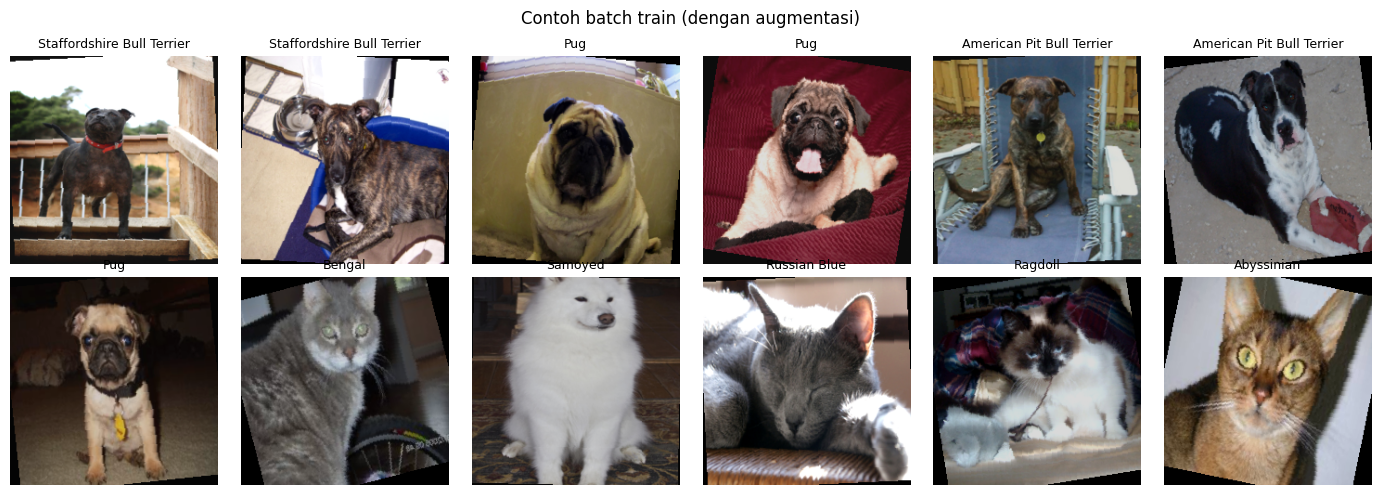

In [4]:
RESNET_WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
eval_tf = RESNET_WEIGHTS.transforms()   # Resize(256) -> CenterCrop(224) -> ToTensor -> Normalize(ImageNet)

train_aug_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=CFG["imagenet_mean"], std=CFG["imagenet_std"]),
])
print(eval_tf)

class PetSubset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), list(labels), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), int(self.labels[i])

def make_loader(split_idx, transform, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(
        PetSubset(paths[split_idx], labels[split_idx], transform),
        batch_size=CFG["batch_size"], shuffle=shuffle, num_workers=CFG["num_workers"],
        pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker, generator=g,
    )

def get_loaders(augment: bool):
    return {
        "train": make_loader(train_idx, train_aug_tf if augment else eval_tf, shuffle=True),
        "train_eval": make_loader(train_idx, eval_tf, shuffle=False),  # clean train set, for measuring the true train accuracy
        "val": make_loader(val_idx, eval_tf, shuffle=False),
        "test": make_loader(test_idx, eval_tf, shuffle=False),
    }

# Quick visual check of augmented training samples
def denorm(t):
    m = torch.tensor(CFG["imagenet_mean"]).view(3, 1, 1)
    s = torch.tensor(CFG["imagenet_std"]).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(get_loaders(augment=True)["train"]))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(denorm(x)); ax.set_title(CLASS_NAMES[y], fontsize=9); ax.axis("off")
plt.suptitle("Contoh batch train (dengan augmentasi)")
plt.tight_layout(); plt.savefig(FIG_DIR / "sample_augmented_batch.png", dpi=120); plt.show()

## 4. Model builder: strategi pembekuan/pembukaan layer dan param group
Satu fungsi `build_model()` menangani semua strategi. Learning rate didefinisikan per param group sehingga bisa dicatat ke log.

**Catatan penting soal BatchNorm saat backbone dibekukan:** `requires_grad=False` hanya menghentikan update bobot (γ, β), **bukan** running mean/variance BatchNorm. Jika model berada di mode `train()`, statistik BN pada layer beku tetap bergeser mengikuti data baru, sehingga backbone tidak benar-benar beku. Karena itu `freeze_bn_stats()` mengembalikan BN pada bagian yang dibekukan ke mode `eval()` di setiap epoch.

In [5]:
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def freeze_bn_stats(model):
    # Put BatchNorm layers whose parameters are all frozen into eval mode,
    # so their running mean/var stay at the pretrained (ImageNet) values.
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            params = list(m.parameters())
            if params and not any(p.requires_grad for p in params):
                m.eval()

def build_model(arch: str, strategy: str):
    # Returns (model, param_groups). Each param group = {"name", "params", "lr"}.
    assert strategy in {"scratch", "feature_extraction", "finetune"}

    if arch == "resnet18":
        weights = None if strategy == "scratch" else models.ResNet18_Weights.IMAGENET1K_V1
        model = models.resnet18(weights=weights)
        if strategy != "scratch":
            for p in model.parameters():
                p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)  # new head, trainable by default

        if strategy == "scratch":
            groups = [{"name": "all", "params": list(model.parameters()), "lr": 1e-3}]
        elif strategy == "feature_extraction":
            groups = [{"name": "fc", "params": list(model.fc.parameters()), "lr": 1e-3}]
        else:  # finetune: unfreeze the last residual stage
            for p in model.layer4.parameters():
                p.requires_grad = True
            groups = [
                {"name": "layer4", "params": list(model.layer4.parameters()), "lr": 1e-4},
                {"name": "fc", "params": list(model.fc.parameters()), "lr": 1e-3},
            ]

    elif arch == "efficientnet_b0":
        assert strategy != "scratch"
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
        head = list(model.classifier.parameters())
        if strategy == "feature_extraction":
            groups = [{"name": "classifier", "params": head, "lr": 1e-3}]
        else:
            # Analogue of ResNet's layer4: the last MBConv stage (features[7]) + final 1x1 conv (features[8])
            last_blocks = nn.ModuleList([model.features[7], model.features[8]])
            for p in last_blocks.parameters():
                p.requires_grad = True
            groups = [
                {"name": "features[7:9]", "params": list(last_blocks.parameters()), "lr": 1e-4},
                {"name": "classifier", "params": head, "lr": 1e-3},
            ]
    else:
        raise ValueError(arch)

    return model.to(DEVICE), groups

# Sanity check from the assignment tips: frozen ResNet-18 backbone -> only 5,130 trainable params
for strat in ["scratch", "feature_extraction", "finetune"]:
    m, _ = build_model("resnet18", strat)
    tr, tot = count_params(m)
    print(f"resnet18 / {strat:<19} trainable = {tr:>12,} / {tot:,}")
    if strat == "feature_extraction":
        assert tr == 5_130, tr
    del m

resnet18 / scratch             trainable =   11,181,642 / 11,181,642
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


resnet18 / feature_extraction  trainable =        5,130 / 11,181,642
resnet18 / finetune            trainable =    8,398,858 / 11,181,642


## 5. Training loop: early stopping pada validation loss + logging per epoch
- Early stopping: berhenti jika `val_loss` tidak membaik (> `min_delta`) selama `patience=5` epoch. Bobot epoch terbaik dikembalikan.
- Log per epoch: `train_loss, train_acc, val_loss, val_acc, epoch_time_s`, plus LR tiap param group.

In [6]:
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    # Returns loss, accuracy, y_true, y_pred, softmax probabilities
    model.eval()
    total_loss, ys, preds, probs = 0.0, [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        p = out.softmax(dim=1)
        ys.append(y.cpu()); preds.append(p.argmax(1).cpu()); probs.append(p.cpu())
    ys, preds, probs = torch.cat(ys).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy()
    return total_loss / len(ys), accuracy_score(ys, preds), ys, preds, probs

def train_model(run_name, model, groups, loaders):
    optimizer = torch.optim.AdamW(
        [{"params": g["params"], "lr": g["lr"]} for g in groups],
        weight_decay=CFG["weight_decay"],
    )
    best_val_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    history = []
    t_start = time.time()

    for epoch in range(1, CFG["max_epochs"] + 1):
        t_ep = time.time()
        model.train()
        freeze_bn_stats(model)
        run_loss, correct, n = 0.0, 0, 0
        for x, y in loaders["train"]:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)

        val_loss, val_acc, *_ = evaluate(model, loaders["val"])
        row = {
            "run": run_name, "epoch": epoch,
            "train_loss": run_loss / n, "train_acc": correct / n,
            "val_loss": val_loss, "val_acc": val_acc,
            "epoch_time_s": time.time() - t_ep,
        }
        for g, pg in zip(groups, optimizer.param_groups):
            row[f"lr_{g['name']}"] = pg["lr"]
        history.append(row)

        improved = val_loss < best_val_loss - CFG["min_delta"]
        if improved:
            best_val_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
        print(f"[{run_name}] ep {epoch:02d} | train loss {row['train_loss']:.4f} acc {row['train_acc']:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} | {row['epoch_time_s']:.1f}s" + ("  *" if improved else ""))
        if wait >= CFG["patience"]:
            print(f"[{run_name}] early stopping at epoch {epoch} (best epoch = {best_epoch})")
            break

    train_time = time.time() - t_start
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {"best_epoch": best_epoch, "epochs_ran": len(history), "train_time_s": train_time}

## 6. Runner eksperimen: latih → evaluasi → simpan log mentah
Setiap run menghasilkan:
- `logs/<run>_epochs.csv`: log per epoch (sumber kurva loss)
- `predictions/<run>_test_predictions.csv`: prediksi + confidence untuk tiap citra test
- `checkpoints/<run>.pt`: bobot terbaik
- satu baris di `results_summary.csv` dan `results_summary.json`

Kolom `gap_train_val_acc` = akurasi train (pada epoch terbaik) − akurasi validasi, sebagai indikator overfitting untuk B4.

In [7]:
SUMMARY_CSV = OUT_DIR / "results_summary.csv"
RESULTS = {}  # run_name -> {"model", "summary", "history", "test"}

def load_summary():
    return pd.read_csv(SUMMARY_CSV) if SUMMARY_CSV.exists() else pd.DataFrame()

def save_summary_row(row):
    df = load_summary()
    if len(df):
        df = df[df["run"] != row["run"]]
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(SUMMARY_CSV, index=False)
    df.to_json(OUT_DIR / "results_summary.json", orient="records", indent=2)

def run_experiment(run_name, description, arch, strategy, augment):
    seed_everything()  # same seed at the start of every run -> fair comparison
    loaders = get_loaders(augment)
    model, groups = build_model(arch, strategy)
    trainable, total = count_params(model)
    lr_str = "; ".join(f"{g['name']}={g['lr']:.0e}" for g in groups)
    print(f"\n=== {run_name}: {description}\n    trainable params: {trainable:,} / {total:,} | LR: {lr_str} | augment={augment}")

    ckpt_path, log_path = CKPT_DIR / f"{run_name}.pt", LOG_DIR / f"{run_name}_epochs.csv"
    prev = load_summary()
    already_done = (not FORCE_RERUN) and ckpt_path.exists() and log_path.exists() \
        and len(prev) and (prev["run"] == run_name).any()

    if already_done:
        print("    checkpoint found -> loading instead of retraining (set FORCE_RERUN=True to retrain)")
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        history = pd.read_csv(log_path)
        summary = prev[prev["run"] == run_name].iloc[0].to_dict()
    else:
        model, history, info = train_model(run_name, model, groups, loaders)
        history.to_csv(log_path, index=False)
        torch.save(model.state_dict(), ckpt_path)
        best = history[history["epoch"] == info["best_epoch"]].iloc[0]
        summary = {
            "run": run_name, "description": description, "arch": arch, "strategy": strategy,
            "augmentation": augment, "trainable_params": trainable, "total_params": total,
            "lr_per_group": lr_str, "epochs_ran": info["epochs_ran"], "best_epoch": info["best_epoch"],
            "train_time_s": round(info["train_time_s"], 1),
            "train_acc_at_best": best["train_acc"], "val_loss_at_best": best["val_loss"],
            "val_acc": best["val_acc"],
            "gap_train_val_acc": best["train_acc"] - best["val_acc"],
        }

    # Final evaluation with restored best weights (clean transforms only)
    _, train_clean_acc, *_ = evaluate(model, loaders["train_eval"])
    _, val_acc, *_ = evaluate(model, loaders["val"])
    test_loss, test_acc, y_true, y_pred, probs = evaluate(model, loaders["test"])
    summary.update({
        "train_acc_clean": train_clean_acc,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "test_macro_f1": f1_score(y_true, y_pred, average="macro"),
        "test_loss": test_loss,
    })
    save_summary_row(summary)

    top2 = np.argsort(-probs, axis=1)[:, :2]
    pd.DataFrame({
        "path": paths[test_idx], "true": [CLASS_NAMES[i] for i in y_true],
        "pred": [CLASS_NAMES[i] for i in y_pred], "confidence": probs.max(1),
        "second_pred": [CLASS_NAMES[i] for i in top2[:, 1]],
        "second_prob": probs[np.arange(len(probs)), top2[:, 1]],
        "correct": y_true == y_pred,
    }).to_csv(PRED_DIR / f"{run_name}_test_predictions.csv", index=False)

    print(f"    -> val acc {val_acc:.4f} | test acc {test_acc:.4f} | test macro-F1 {summary['test_macro_f1']:.4f} | "
          f"epochs {summary['epochs_ran']} | time {summary['train_time_s']}s")
    RESULTS[run_name] = {"model": model, "summary": summary, "history": history,
                         "test": {"y_true": y_true, "y_pred": y_pred, "probs": probs}}
    return RESULTS[run_name]

## 7. B1: Baseline from scratch (`weights=None`)

In [8]:
run_experiment("B1_scratch", "ResNet-18 from random init, all layers trainable", "resnet18", "scratch", augment=True);


=== B1_scratch: ResNet-18 from random init, all layers trainable
    trainable params: 11,181,642 / 11,181,642 | LR: all=1e-03 | augment=True
[B1_scratch] ep 01 | train loss 2.2705 acc 0.1986 | val loss 2.7816 acc 0.2215 | 17.0s  *
[B1_scratch] ep 02 | train loss 2.0253 acc 0.2568 | val loss 1.7668 acc 0.3490 | 13.9s  *
[B1_scratch] ep 03 | train loss 1.8873 acc 0.3273 | val loss 1.8391 acc 0.3087 | 13.9s
[B1_scratch] ep 04 | train loss 1.8423 acc 0.3432 | val loss 1.8965 acc 0.3322 | 14.2s
[B1_scratch] ep 05 | train loss 1.7425 acc 0.3734 | val loss 1.9154 acc 0.3188 | 14.0s
[B1_scratch] ep 06 | train loss 1.6837 acc 0.4000 | val loss 1.6143 acc 0.4362 | 21.3s  *
[B1_scratch] ep 07 | train loss 1.6207 acc 0.4209 | val loss 1.8983 acc 0.3490 | 16.9s
[B1_scratch] ep 08 | train loss 1.5610 acc 0.4338 | val loss 1.5940 acc 0.4497 | 13.8s  *
[B1_scratch] ep 09 | train loss 1.4904 acc 0.4719 | val loss 1.5959 acc 0.4295 | 13.8s
[B1_scratch] ep 10 | train loss 1.4331 acc 0.4993 | val loss 1

## 8. B2: Feature extraction (backbone beku, hanya `fc` dilatih)

In [9]:
run_experiment("B2_feature_extraction", "Pretrained ResNet-18, frozen backbone, train fc only", "resnet18", "feature_extraction", augment=True);


=== B2_feature_extraction: Pretrained ResNet-18, frozen backbone, train fc only
    trainable params: 5,130 / 11,181,642 | LR: fc=1e-03 | augment=True
[B2_feature_extraction] ep 01 | train loss 1.3355 acc 0.5914 | val loss 0.6869 acc 0.7987 | 13.6s  *
[B2_feature_extraction] ep 02 | train loss 0.5621 acc 0.8576 | val loss 0.4448 acc 0.8624 | 13.6s  *
[B2_feature_extraction] ep 03 | train loss 0.3965 acc 0.8957 | val loss 0.3905 acc 0.8591 | 13.6s  *
[B2_feature_extraction] ep 04 | train loss 0.3401 acc 0.8986 | val loss 0.3393 acc 0.8792 | 13.6s  *
[B2_feature_extraction] ep 05 | train loss 0.2893 acc 0.9173 | val loss 0.3000 acc 0.8792 | 13.0s  *
[B2_feature_extraction] ep 06 | train loss 0.2740 acc 0.9180 | val loss 0.2924 acc 0.8792 | 12.6s  *
[B2_feature_extraction] ep 07 | train loss 0.2596 acc 0.9165 | val loss 0.2760 acc 0.8893 | 13.6s  *
[B2_feature_extraction] ep 08 | train loss 0.2382 acc 0.9324 | val loss 0.2671 acc 0.8826 | 13.7s  *
[B2_feature_extraction] ep 09 | train lo

## 9. B3: Progressive fine-tuning (`layer4` + `fc`, differential LR)

In [10]:
run_experiment("B3_finetune_layer4", "Pretrained ResNet-18, unfreeze layer4 + fc, LR 1e-4 / 1e-3", "resnet18", "finetune", augment=True);


=== B3_finetune_layer4: Pretrained ResNet-18, unfreeze layer4 + fc, LR 1e-4 / 1e-3
    trainable params: 8,398,858 / 11,181,642 | LR: layer4=1e-04; fc=1e-03 | augment=True
[B3_finetune_layer4] ep 01 | train loss 0.7737 acc 0.7482 | val loss 0.2678 acc 0.9027 | 13.8s  *
[B3_finetune_layer4] ep 02 | train loss 0.2446 acc 0.9158 | val loss 0.2269 acc 0.8960 | 13.9s  *
[B3_finetune_layer4] ep 03 | train loss 0.1594 acc 0.9439 | val loss 0.2626 acc 0.8859 | 13.8s
[B3_finetune_layer4] ep 04 | train loss 0.1001 acc 0.9676 | val loss 0.2387 acc 0.9027 | 14.0s
[B3_finetune_layer4] ep 05 | train loss 0.0630 acc 0.9863 | val loss 0.2288 acc 0.9128 | 13.6s
[B3_finetune_layer4] ep 06 | train loss 0.0462 acc 0.9878 | val loss 0.2881 acc 0.9027 | 13.2s
[B3_finetune_layer4] ep 07 | train loss 0.0375 acc 0.9914 | val loss 0.2391 acc 0.9262 | 12.7s
[B3_finetune_layer4] early stopping at epoch 7 (best epoch = 2)
    -> val acc 0.8960 | test acc 0.9064 | test macro-F1 0.9029 | epochs 7 | time 95.0s


## 10. B4: Uji kontrol augmentasi (berbasis B3)
- **Dengan augmentasi** = B3 (konfigurasinya identik, jadi tidak dilatih ulang)
- **Tanpa augmentasi** = B3 dengan train transform hanya Resize/CenterCrop + Normalize

In [11]:
run_experiment("B4_finetune_no_aug", "B3 config WITHOUT augmentation (resize/crop + normalize only)", "resnet18", "finetune", augment=False);

b4 = pd.DataFrame([RESULTS["B3_finetune_layer4"]["summary"], RESULTS["B4_finetune_no_aug"]["summary"]])
b4.insert(0, "B4_scenario", ["with augmentation (=B3)", "without augmentation"])
display(b4[["B4_scenario", "train_acc_at_best", "val_acc", "gap_train_val_acc", "train_acc_clean",
            "test_acc", "test_macro_f1", "epochs_ran", "best_epoch"]].round(4))


=== B4_finetune_no_aug: B3 config WITHOUT augmentation (resize/crop + normalize only)
    trainable params: 8,398,858 / 11,181,642 | LR: layer4=1e-04; fc=1e-03 | augment=False
[B4_finetune_no_aug] ep 01 | train loss 0.6990 acc 0.7597 | val loss 0.2673 acc 0.8960 | 10.3s  *
[B4_finetune_no_aug] ep 02 | train loss 0.1205 acc 0.9705 | val loss 0.2178 acc 0.9195 | 10.4s  *
[B4_finetune_no_aug] ep 03 | train loss 0.0449 acc 0.9935 | val loss 0.2405 acc 0.9027 | 8.5s
[B4_finetune_no_aug] ep 04 | train loss 0.0192 acc 0.9978 | val loss 0.2368 acc 0.9161 | 10.4s
[B4_finetune_no_aug] ep 05 | train loss 0.0101 acc 0.9993 | val loss 0.2492 acc 0.9027 | 10.1s
[B4_finetune_no_aug] ep 06 | train loss 0.0053 acc 1.0000 | val loss 0.2408 acc 0.9060 | 8.8s
[B4_finetune_no_aug] ep 07 | train loss 0.0045 acc 1.0000 | val loss 0.2553 acc 0.9094 | 10.7s
[B4_finetune_no_aug] early stopping at epoch 7 (best epoch = 2)
    -> val acc 0.9195 | test acc 0.9064 | test macro-F1 0.9045 | epochs 7 | time 69.3s


,B4_scenario,train_acc_at_best,val_acc,gap_train_val_acc,train_acc_clean,test_acc,test_macro_f1,epochs_ran,best_epoch
0,with augmentation (=B3),0.9158,0.8960,0.0199,0.9633,0.9064,0.9029,7,2
1,without augmentation,0.9705,0.9195,0.0510,0.9993,0.9064,0.9045,7,2


## 11. B5 (Bonus): Konfigurasi terbaik pada EfficientNet-B0
Konfigurasi "terbaik" dipilih **berdasarkan akurasi validasi** (bukan test, supaya test set tetap tidak tersentuh dalam pengambilan keputusan) dari B2, B3, dan B4.

In [12]:
candidates = ["B2_feature_extraction", "B3_finetune_layer4", "B4_finetune_no_aug"]
best_cfg = max(candidates, key=lambda r: (RESULTS[r]["summary"]["val_acc"], -RESULTS[r]["summary"]["val_loss_at_best"]))
best_strategy = RESULTS[best_cfg]["summary"]["strategy"]
best_augment = bool(RESULTS[best_cfg]["summary"]["augmentation"])
print(f"Best ResNet-18 config by val acc: {best_cfg} -> strategy={best_strategy}, augment={best_augment}")

run_experiment("B5_efficientnet_b0", f"EfficientNet-B0 with best config ({best_cfg})",
               "efficientnet_b0", best_strategy, augment=best_augment);

Best ResNet-18 config by val acc: B4_finetune_no_aug -> strategy=finetune, augment=False
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 156MB/s]



=== B5_efficientnet_b0: EfficientNet-B0 with best config (B4_finetune_no_aug)
    trainable params: 1,142,202 / 4,020,358 | LR: features[7:9]=1e-04; classifier=1e-03 | augment=False
[B5_efficientnet_b0] ep 01 | train loss 1.0208 acc 0.7532 | val loss 0.3029 acc 0.9094 | 9.4s  *
[B5_efficientnet_b0] ep 02 | train loss 0.2553 acc 0.9281 | val loss 0.2013 acc 0.9094 | 9.9s  *
[B5_efficientnet_b0] ep 03 | train loss 0.1723 acc 0.9468 | val loss 0.1771 acc 0.9094 | 10.7s  *
[B5_efficientnet_b0] ep 04 | train loss 0.1282 acc 0.9619 | val loss 0.1623 acc 0.9262 | 10.0s  *
[B5_efficientnet_b0] ep 05 | train loss 0.0953 acc 0.9748 | val loss 0.1613 acc 0.9262 | 9.4s  *
[B5_efficientnet_b0] ep 06 | train loss 0.0806 acc 0.9755 | val loss 0.1634 acc 0.9228 | 10.7s
[B5_efficientnet_b0] ep 07 | train loss 0.0658 acc 0.9842 | val loss 0.1534 acc 0.9295 | 9.5s  *
[B5_efficientnet_b0] ep 08 | train loss 0.0480 acc 0.9906 | val loss 0.1604 acc 0.9262 | 9.6s
[B5_efficientnet_b0] ep 09 | train loss 0.04

## 12. C1: Tabel konsolidasi seluruh kondisi

In [13]:
summary_df = load_summary()
order = ["B1_scratch", "B2_feature_extraction", "B3_finetune_layer4", "B4_finetune_no_aug", "B5_efficientnet_b0"]
summary_df = summary_df.set_index("run").loc[[r for r in order if r in set(summary_df["run"])]].reset_index()

table = summary_df[["run", "strategy", "arch", "augmentation", "trainable_params", "lr_per_group",
                    "epochs_ran", "best_epoch", "train_time_s", "train_acc_at_best", "val_acc",
                    "gap_train_val_acc", "test_acc", "test_macro_f1"]].copy()
display(table.round(4))
table.round(4).to_csv(OUT_DIR / "C1_consolidated_table.csv", index=False)
try:
    (OUT_DIR / "C1_consolidated_table.md").write_text(table.round(4).to_markdown(index=False))
except ImportError:
    pass

,run,strategy,arch,augmentation,trainable_params,lr_per_group,epochs_ran,best_epoch,train_time_s,train_acc_at_best,val_acc,gap_train_val_acc,test_acc,test_macro_f1
0,B1_scratch,scratch,resnet18,True,11181642,all=1e-03,15,10,227.5,0.4993,0.4933,0.0060,0.4615,0.4591
1,B2_feature_extraction,feature_extraction,resnet18,True,5130,fc=1e-03,27,22,364.2,0.9511,0.9027,0.0484,0.8896,0.8885
2,B3_finetune_layer4,finetune,resnet18,True,8398858,layer4=1e-04; fc=1e-03,7,2,95.0,0.9158,0.8960,0.0199,0.9064,0.9029
3,B4_finetune_no_aug,finetune,resnet18,False,8398858,layer4=1e-04; fc=1e-03,7,2,69.3,0.9705,0.9195,0.0510,0.9064,0.9045
4,B5_efficientnet_b0,finetune,efficientnet_b0,False,1142202,features[7:9]=1e-04; classifier=1e-03,12,7,120.8,0.9842,0.9295,0.0546,0.9498,0.9495


### Kurva training loss vs. validation loss (B1, B2, B3)

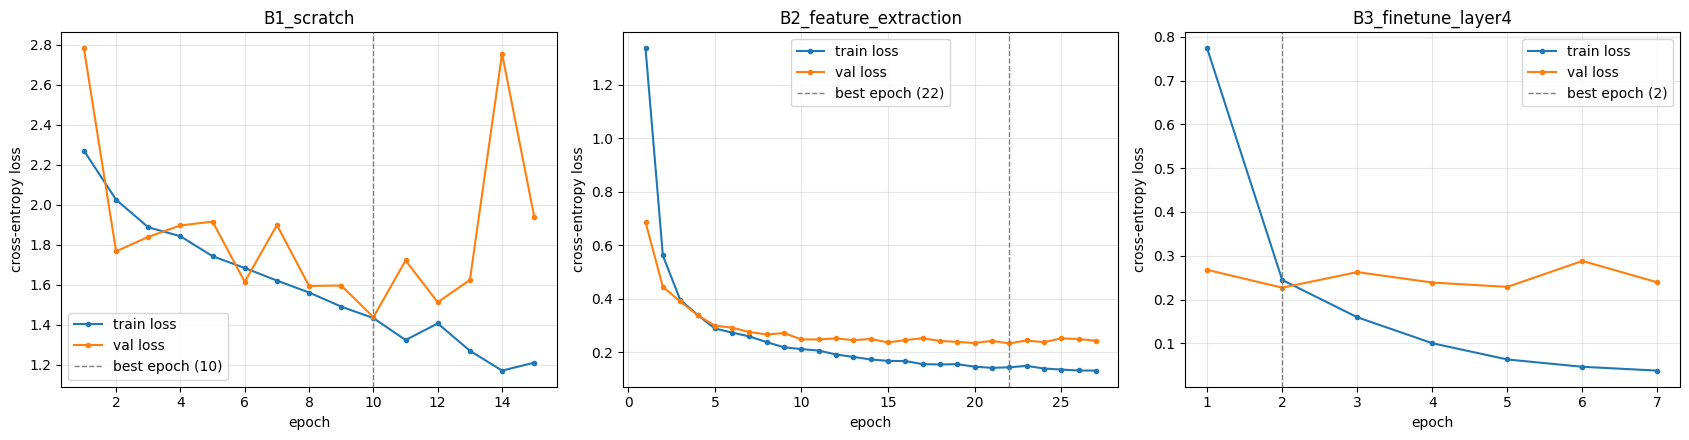

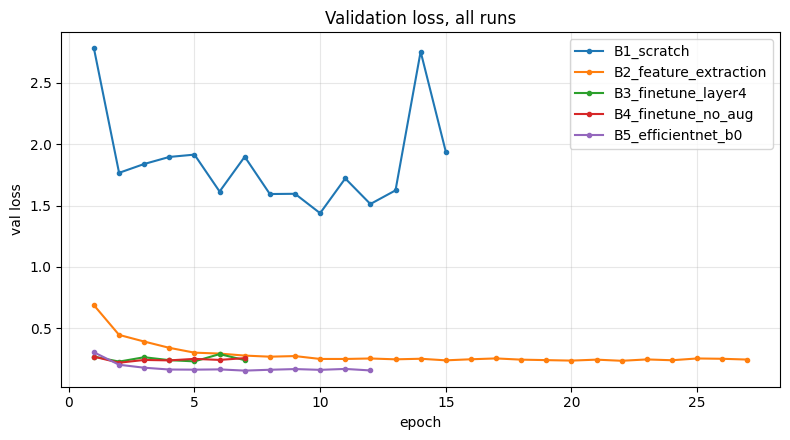

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=False)
for ax, run in zip(axes, ["B1_scratch", "B2_feature_extraction", "B3_finetune_layer4"]):
    h = RESULTS[run]["history"]
    best_ep = int(RESULTS[run]["summary"]["best_epoch"])
    ax.plot(h["epoch"], h["train_loss"], marker="o", ms=3, label="train loss")
    ax.plot(h["epoch"], h["val_loss"], marker="o", ms=3, label="val loss")
    ax.axvline(best_ep, ls="--", c="gray", lw=1, label=f"best epoch ({best_ep})")
    ax.set_title(run); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "C1_loss_curves_B1_B2_B3.png", dpi=150); plt.show()

# All runs on one axis (val loss) for a direct comparison
plt.figure(figsize=(8, 4.5))
for run in RESULTS:
    h = RESULTS[run]["history"]
    plt.plot(h["epoch"], h["val_loss"], marker="o", ms=3, label=run)
plt.xlabel("epoch"); plt.ylabel("val loss"); plt.title("Validation loss, all runs"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "C1_val_loss_all_runs.png", dpi=150); plt.show()

### B4: Train vs. validation accuracy (dengan vs. tanpa augmentasi)

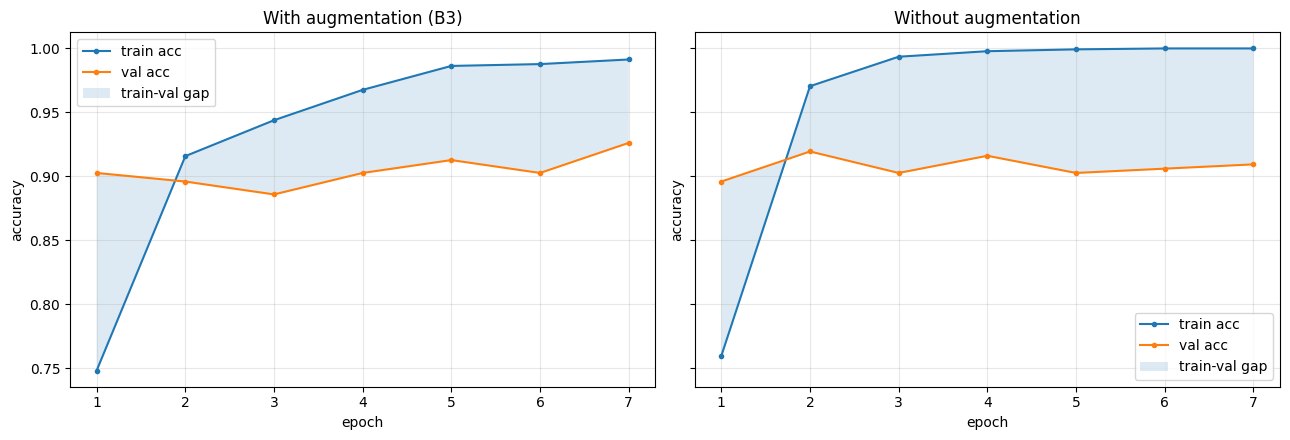

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, run, title in zip(axes, ["B3_finetune_layer4", "B4_finetune_no_aug"], ["With augmentation (B3)", "Without augmentation"]):
    h = RESULTS[run]["history"]
    ax.plot(h["epoch"], h["train_acc"], marker="o", ms=3, label="train acc")
    ax.plot(h["epoch"], h["val_acc"], marker="o", ms=3, label="val acc")
    ax.fill_between(h["epoch"], h["val_acc"], h["train_acc"], alpha=.15, label="train-val gap")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "C2_B4_augmentation_gap.png", dpi=150); plt.show()

### Ringkasan performa vs. efisiensi (termasuk B5)

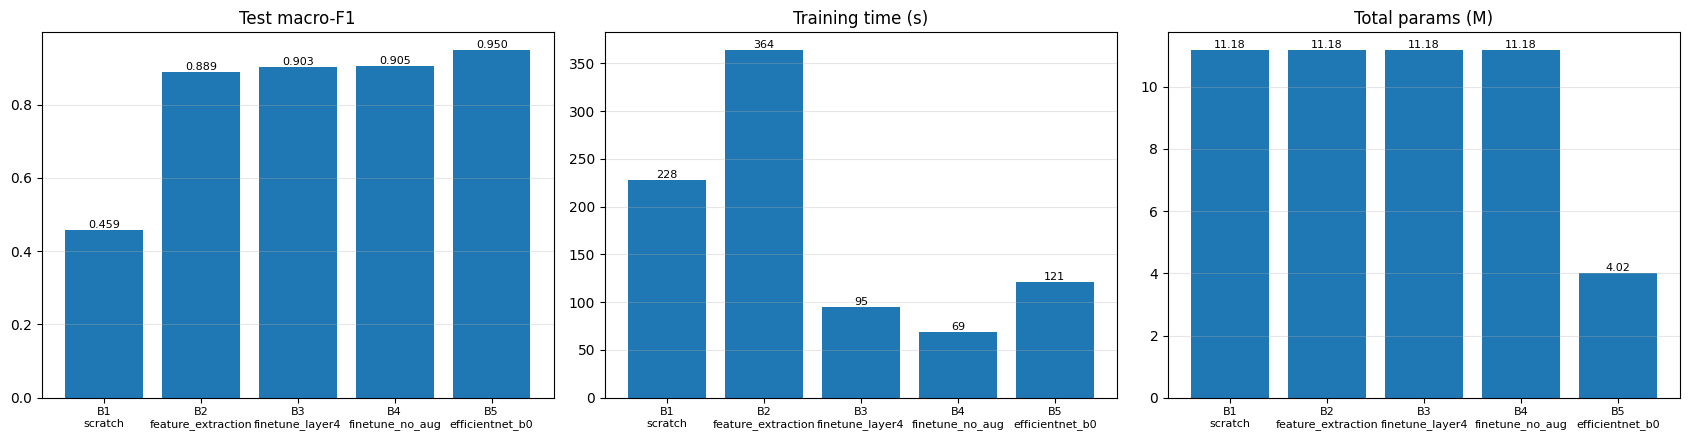

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
names = summary_df["run"].str.replace("_", "\n", n=1)
axes[0].bar(names, summary_df["test_macro_f1"]); axes[0].set_title("Test macro-F1")
axes[1].bar(names, summary_df["train_time_s"]); axes[1].set_title("Training time (s)")
axes[2].bar(names, summary_df["total_params"] / 1e6); axes[2].set_title("Total params (M)")
for ax, col, fmt in zip(axes, ["test_macro_f1", "train_time_s", "total_params"], ["{:.3f}", "{:.0f}", "{:.2f}"]):
    for i, v in enumerate(summary_df[col]):
        ax.text(i, (v / 1e6 if col == "total_params" else v), fmt.format(v / 1e6 if col == "total_params" else v),
                ha="center", va="bottom", fontsize=8)
    ax.tick_params(axis="x", labelsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "C1_performance_vs_efficiency.png", dpi=150); plt.show()

## 13. C3: Failure analysis pada model terbaik
Model terbaik dipilih berdasarkan **akurasi validasi** dari semua run. Ditampilkan 8 kesalahan dengan confidence tertinggi (kesalahan yang paling "yakin" biasanya paling informatif), lengkap dengan prediksi kedua.
File `C3_misclassified.csv` punya kolom `hypothesis` kosong untuk diisi sendiri setelah melihat gambarnya.

Best model (by val acc): B5_efficientnet_b0
                            precision    recall  f1-score   support

                Abyssinian     0.9091    1.0000    0.9524        30
                    Bengal     1.0000    0.9333    0.9655        30
                    Birman     0.9630    0.8667    0.9123        30
                   Ragdoll     0.8788    0.9667    0.9206        30
              Russian Blue     1.0000    0.9667    0.9831        30
 American Pit Bull Terrier     0.9600    0.8000    0.8727        30
Staffordshire Bull Terrier     0.8235    0.9655    0.8889        29
                    Beagle     1.0000    1.0000    1.0000        30
                       Pug     1.0000    1.0000    1.0000        30
                   Samoyed     1.0000    1.0000    1.0000        30

                  accuracy                         0.9498       299
                 macro avg     0.9534    0.9499    0.9495       299
              weighted avg     0.9539    0.9498    0.9498       299



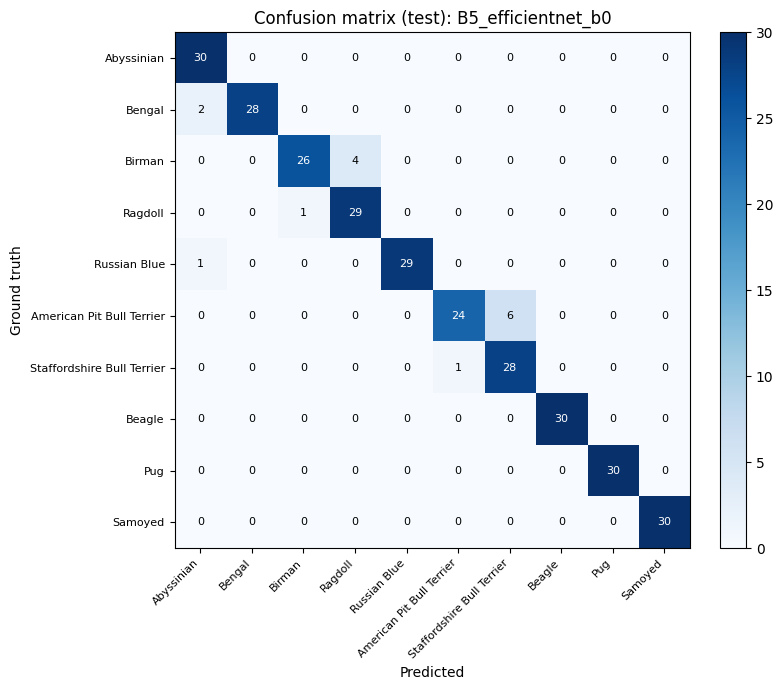

Misclassified test images: 15 / 299; showing 8


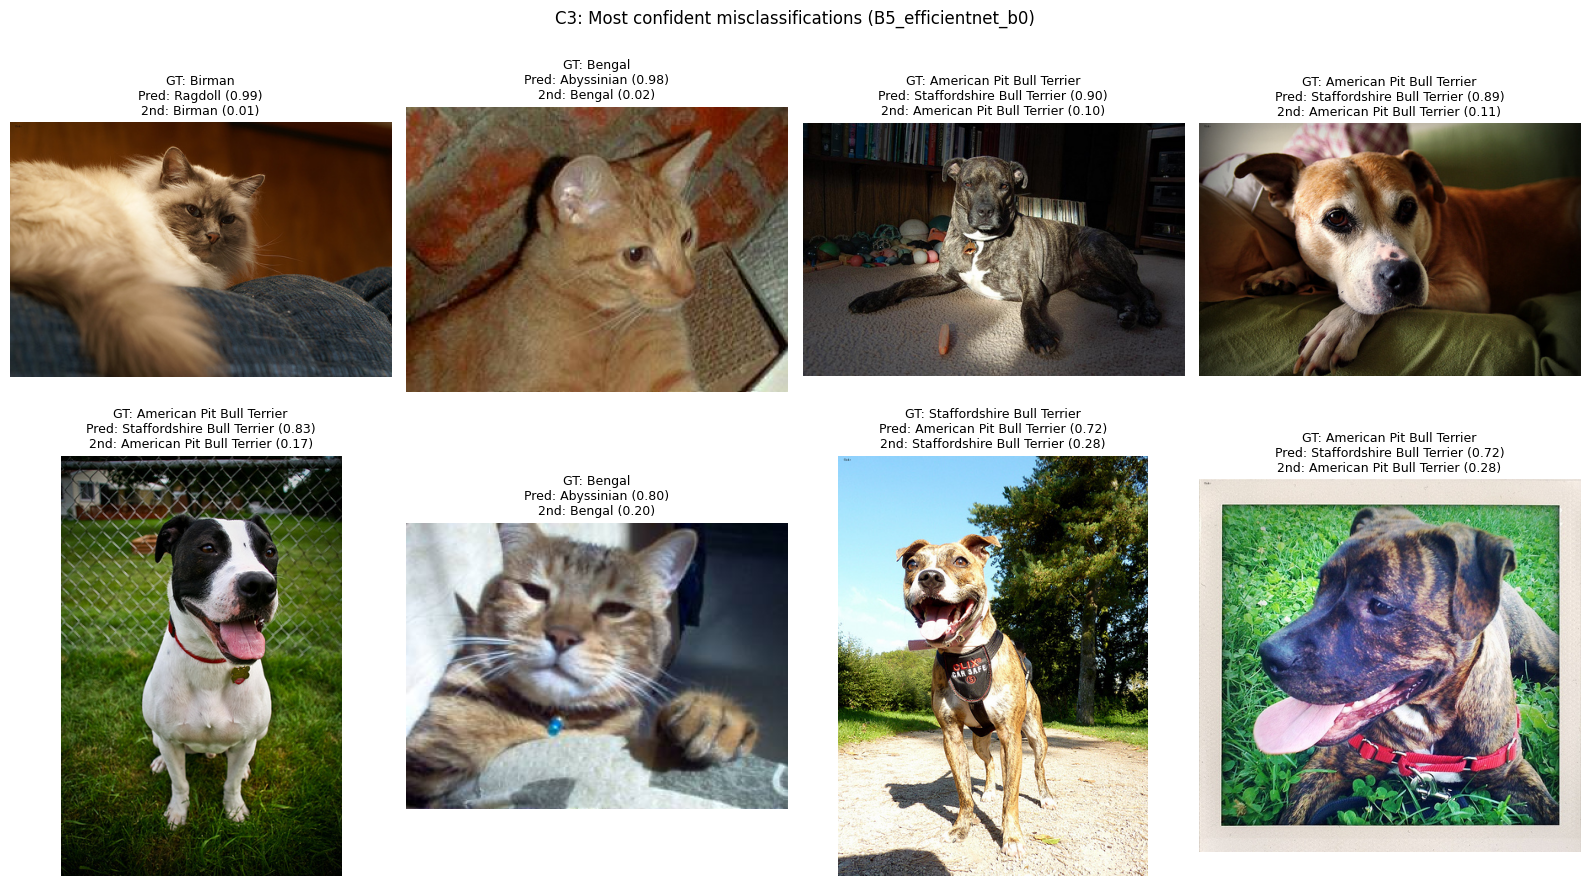

,file,ground_truth,prediction,confidence,second_pred,second_prob,hypothesis
0,Birman_79.jpg,Birman,Ragdoll,0.9855,Birman,0.0140,
1,Bengal_134.jpg,Bengal,Abyssinian,0.9816,Bengal,0.0178,
2,american_pit_bull_terrier_1.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.8992,American Pit Bull Terrier,0.0996,
3,american_pit_bull_terrier_26.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.8911,American Pit Bull Terrier,0.1056,
4,american_pit_bull_terrier_98.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.8337,American Pit Bull Terrier,0.1653,
5,Bengal_143.jpg,Bengal,Abyssinian,0.7972,Bengal,0.2016,
6,staffordshire_bull_terrier_62.jpg,Staffordshire Bull Terrier,American Pit Bull Terrier,0.7221,Staffordshire Bull Terrier,0.2768,
7,american_pit_bull_terrier_32.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.7209,American Pit Bull Terrier,0.2775,


In [17]:
best_run = max(RESULTS, key=lambda r: (RESULTS[r]["summary"]["val_acc"], -RESULTS[r]["summary"].get("val_loss_at_best", 0)))
print("Best model (by val acc):", best_run)
t = RESULTS[best_run]["test"]
y_true, y_pred, probs = t["y_true"], t["y_pred"], t["probs"]

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth"); ax.set_title(f"Confusion matrix (test): {best_run}")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(FIG_DIR / "C3_confusion_matrix.png", dpi=150); plt.show()

wrong = np.where(y_true != y_pred)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]   # most confident mistakes first
print(f"Misclassified test images: {(y_true != y_pred).sum()} / {len(y_true)}; showing {len(wrong)}")

rows = []
n_cols = 4
fig, axes = plt.subplots(int(np.ceil(len(wrong) / n_cols)) or 1, n_cols, figsize=(16, 9), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong):
    p = paths[test_idx][i]
    second = np.argsort(-probs[i])[1]
    ax.imshow(Image.open(p).convert("RGB"))
    ax.set_title(f"GT: {CLASS_NAMES[y_true[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({probs[i].max():.2f})\n"
                 f"2nd: {CLASS_NAMES[second]} ({probs[i][second]:.2f})", fontsize=9)
    rows.append({"file": Path(p).name, "ground_truth": CLASS_NAMES[y_true[i]], "prediction": CLASS_NAMES[y_pred[i]],
                 "confidence": round(float(probs[i].max()), 4), "second_pred": CLASS_NAMES[second],
                 "second_prob": round(float(probs[i][second]), 4), "hypothesis": ""})
plt.suptitle(f"C3: Most confident misclassifications ({best_run})")
plt.tight_layout(); plt.savefig(FIG_DIR / "C3_misclassified.png", dpi=150); plt.show()

mis_df = pd.DataFrame(rows)
mis_df.to_csv(OUT_DIR / "C3_misclassified.csv", index=False)
display(mis_df)

## 14. C5 (Opsional): Grad-CAM pada `layer4`, sebelum vs. sesudah fine-tuning
- **Sebelum fine-tuning** = model B2: `layer4` masih berisi bobot ImageNet asli (dibekukan), tetapi head-nya sudah memetakan ke 10 ras, jadi target kelasnya sebanding.
- **Sesudah fine-tuning** = model B3: `layer4` sudah disesuaikan ke domain pet breeds.

Grad-CAM dihitung terhadap kelas **ground truth** untuk kedua model (Selvaraju et al., 2017). Di bawahnya ada pengukuran seberapa jauh bobot `layer4` bergeser dari bobot pretrained.

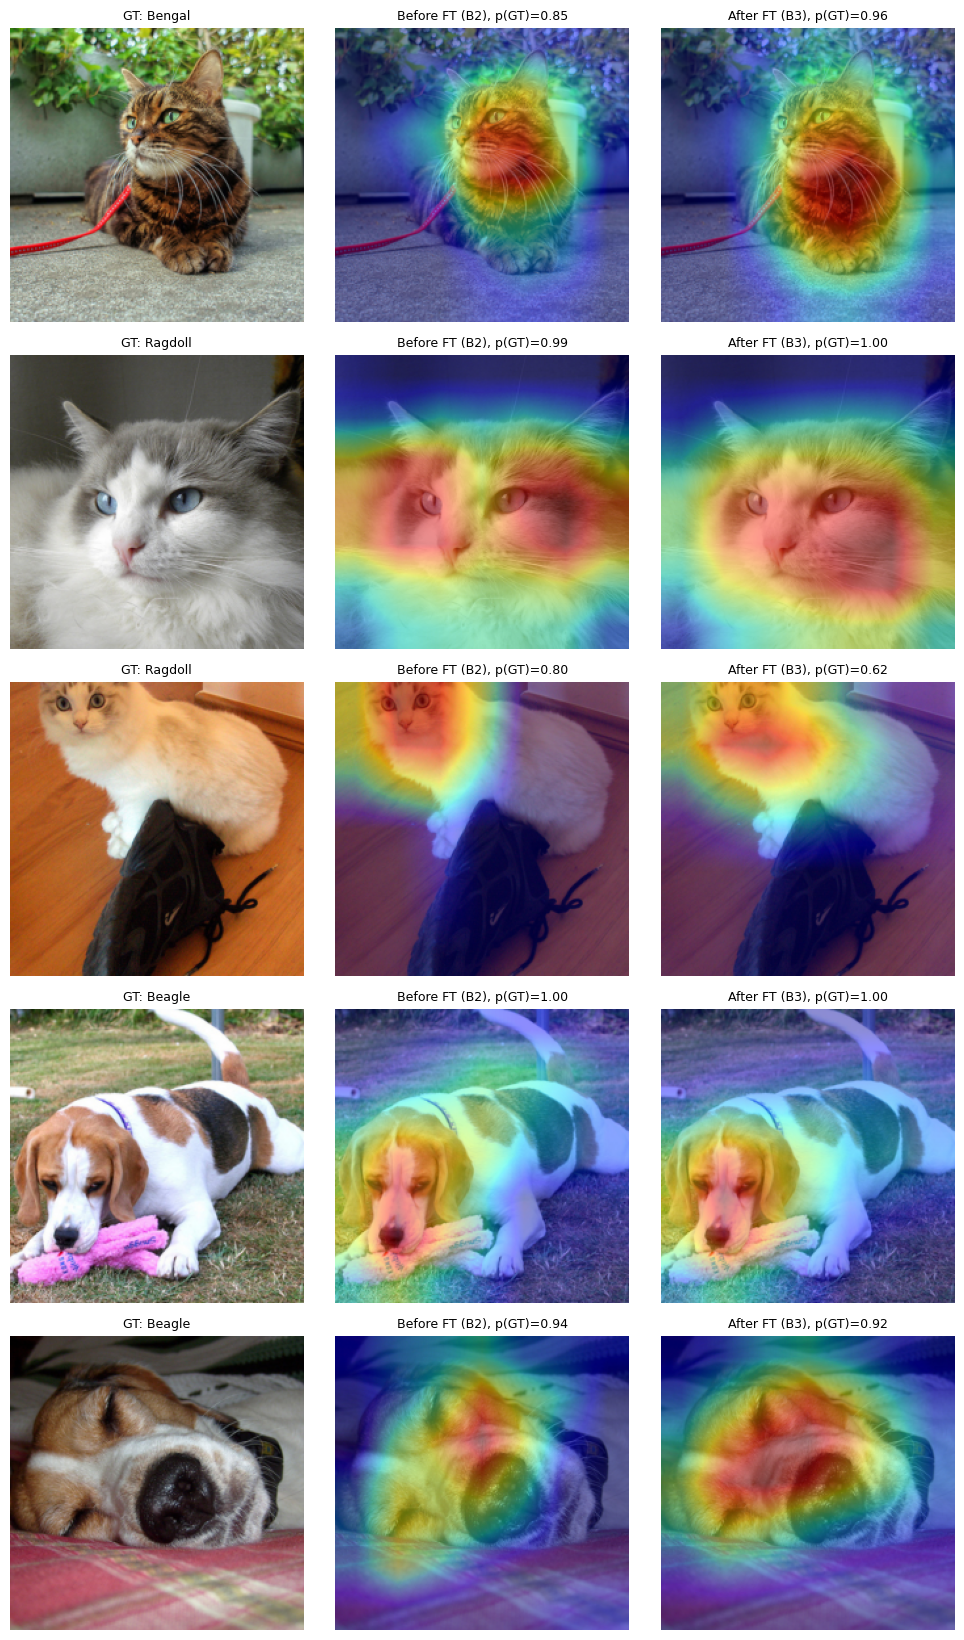

,param,relative_change
0,0.conv1.weight,0.0531
1,0.conv2.weight,0.0597
2,0.downsample.0.weight,0.0328
3,1.conv1.weight,0.0615
4,1.conv2.weight,0.1026


In [18]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = target_layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, class_idx):
        self.model.eval()
        x = x.clone().requires_grad_(True)   # makes gradients flow even when layer4 itself is frozen (B2)
        logits = self.model(x)
        self.model.zero_grad(set_to_none=True)
        logits[0, class_idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)              # channel importance = GAP of gradients
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))     # weighted sum of feature maps
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), logits.softmax(1)[0, class_idx].item()
    def remove(self):
        self.handle.remove()

m_before = RESULTS["B2_feature_extraction"]["model"]
m_after = RESULTS["B3_finetune_layer4"]["model"]
cam_before, cam_after = GradCAM(m_before, m_before.layer4), GradCAM(m_after, m_after.layer4)

rng = np.random.RandomState(SEED)
sample_ids = rng.choice(len(test_idx), size=5, replace=False)
fig, axes = plt.subplots(len(sample_ids), 3, figsize=(10, 3.3 * len(sample_ids)))
for row, i in zip(axes, sample_ids):
    p, y = paths[test_idx][i], labels[test_idx][i]
    x = eval_tf(Image.open(p).convert("RGB")).unsqueeze(0).to(DEVICE)
    img = denorm(x[0].cpu())
    hb, pb = cam_before(x, y)
    ha, pa = cam_after(x, y)
    row[0].imshow(img); row[0].set_title(f"GT: {CLASS_NAMES[y]}", fontsize=9)
    row[1].imshow(img); row[1].imshow(hb, cmap="jet", alpha=0.45); row[1].set_title(f"Before FT (B2), p(GT)={pb:.2f}", fontsize=9)
    row[2].imshow(img); row[2].imshow(ha, cmap="jet", alpha=0.45); row[2].set_title(f"After FT (B3), p(GT)={pa:.2f}", fontsize=9)
    for ax in row:
        ax.axis("off")
cam_before.remove(); cam_after.remove()
plt.tight_layout(); plt.savefig(FIG_DIR / "C5_gradcam_before_after.png", dpi=130); plt.show()

# How far did layer4 weights move from the ImageNet weights during fine-tuning?
pre = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1).layer4.state_dict()
ft = {k: v.cpu() for k, v in m_after.layer4.state_dict().items()}
drift = [{"param": k, "relative_change": ((ft[k].float() - pre[k].float()).norm() / (pre[k].float().norm() + 1e-12)).item()}
         for k in pre if k.endswith("weight") and pre[k].dim() > 1]
drift_df = pd.DataFrame(drift)
drift_df.to_csv(OUT_DIR / "C5_layer4_weight_drift.csv", index=False)
display(drift_df.round(4))

## 15. Ekspor: requirements, environment, dan ZIP seluruh output

In [19]:
import sklearn, matplotlib
req = "\n".join([
    f"torch=={torch.__version__.split('+')[0]}",
    f"torchvision=={torchvision.__version__.split('+')[0]}",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"Pillow=={Image.__version__}",
]) + "\n"
(OUT_DIR / "requirements.txt").write_text(req)
print(req)

with open(OUT_DIR / "env.json", "w") as f:
    json.dump(ENV, f, indent=2)

# Merge all per-epoch logs into one file as well (raw evidence for the report numbers)
all_logs = pd.concat([pd.read_csv(p) for p in sorted(LOG_DIR.glob("*_epochs.csv"))], ignore_index=True)
all_logs.to_csv(OUT_DIR / "all_epoch_logs.csv", index=False)

# Zip everything except checkpoints (too large for LMS); checkpoints stay on Drive
zip_base = Path("/content/Tugas05_outputs_no_ckpt")
tmp = Path("/content/_export"); shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(OUT_DIR, tmp, ignore=shutil.ignore_patterns("checkpoints"))
shutil.make_archive(str(zip_base), "zip", tmp)
print("Zipped ->", str(zip_base) + ".zip")
display(load_summary().round(4))

torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
Pillow==11.3.0

Zipped -> /content/Tugas05_outputs_no_ckpt.zip


,run,description,arch,strategy,augmentation,trainable_params,total_params,lr_per_group,epochs_ran,best_epoch,train_time_s,train_acc_at_best,val_loss_at_best,val_acc,gap_train_val_acc,train_acc_clean,test_acc,test_macro_f1,test_loss
0,B1_scratch,"ResNet-18 from random init, all layers trainable",resnet18,scratch,True,11181642,11181642,all=1e-03,15,10,227.5,0.4993,1.4377,0.4933,0.0060,0.5115,0.4615,0.4591,1.5589
1,B2_feature_extraction,"Pretrained ResNet-18, frozen backbone, train f...",resnet18,feature_extraction,True,5130,11181642,fc=1e-03,27,22,364.2,0.9511,0.2335,0.9027,0.0484,0.9576,0.8896,0.8885,0.2663
2,B3_finetune_layer4,"Pretrained ResNet-18, unfreeze layer4 + fc, LR...",resnet18,finetune,True,8398858,11181642,layer4=1e-04; fc=1e-03,7,2,95.0,0.9158,0.2269,0.8960,0.0199,0.9633,0.9064,0.9029,0.2650
3,B4_finetune_no_aug,B3 config WITHOUT augmentation (resize/crop + ...,resnet18,finetune,False,8398858,11181642,layer4=1e-04; fc=1e-03,7,2,69.3,0.9705,0.2178,0.9195,0.0510,0.9993,0.9064,0.9045,0.2332
4,B5_efficientnet_b0,EfficientNet-B0 with best config (B4_finetune_...,efficientnet_b0,finetune,False,1142202,4020358,features[7:9]=1e-04; classifier=1e-03,12,7,120.8,0.9842,0.1534,0.9295,0.0546,0.9978,0.9498,0.9495,0.1250
